<a href="https://colab.research.google.com/github/mahamtaqi3-cloud/Range-shift-landscape-population-genenetics-simimulation/blob/main/Range_shift_landscape_population_genenetics_simimulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
!pip install -q msprime scikit-allel

import msprime, numpy as np, allel
import matplotlib.pyplot as plt

n = 5                      # grid is n x n
origin = (0, 0)            # true origin of expansion (row, col)
Ne, m = 100, 0.01          # deme size, migration rate between neighbors
step_gens = 50             # generations between colonization steps

def idx(r, c): return r*n + c   # demes are numbered row by row

# Build the 2D grid manually
dem = msprime.Demography()
for r in range(n):
    for c in range(n):
        dem.add_population(name=f"d{idx(r,c)}", initial_size=Ne)

# Migration between 4-connected neighbors (hard edges, no wrap-around)
for r in range(n):
    for c in range(n):
        for dr, dc in [(1,0), (-1,0), (0,1), (0,-1)]:
            rr, cc = r+dr, c+dc
            if 0 <= rr < n and 0 <= cc < n:
                dem.set_migration_rate(f"d{idx(r,c)}", f"d{idx(rr,cc)}", m)

# Sequential colonization outward from the origin
dmax = 2*(n-1)          # largest distance from the origin
Nb, w = 5, 40            # stronger founder bottleneck (w must stay < step_gens)

for r in range(n):
    for c in range(n):
        d = abs(r-origin[0]) + abs(c-origin[1])
        if d == 0:
            continue
        t_found = (dmax - d + 1) * step_gens   # far demes = recent founding
        pr, pc = (r-1, c) if r > origin[0] else (r, c-1) if c > origin[1] else (r, c+1)
        # small founder population right after colonization
        dem.add_population_parameters_change(
            time=t_found - w, population=f"d{idx(r,c)}", initial_size=Nb)
        # before founding, its lineages trace back to the parent deme
        dem.add_mass_migration(time=t_found,
                               source=f"d{idx(r,c)}", dest=f"d{idx(pr,pc)}",
                               proportion=1)
dem.sort_events()

ts = msprime.sim_ancestry(
    samples={f"d{i}": 5 for i in range(n*n)}, demography=dem,
    sequence_length=1e6, recombination_rate=1e-8, random_seed=1)
ts = msprime.sim_mutations(ts, rate=1e-7, random_seed=1)   # was 1e-8
print(ts.num_sites, "variable sites")

2569 variable sites


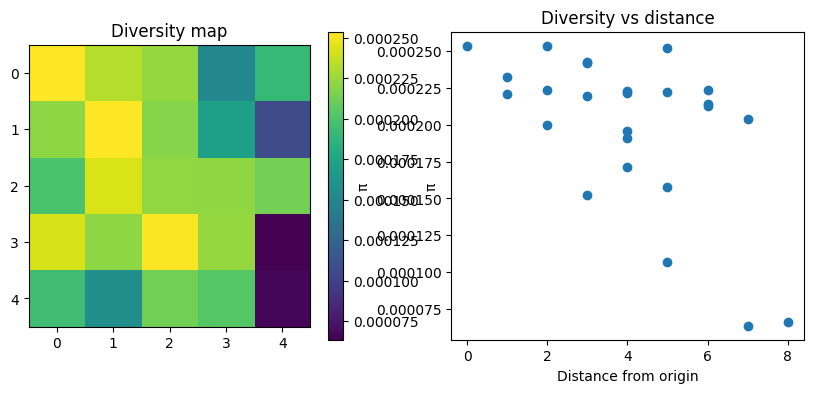

correlation: -0.5711665913671818


In [19]:
het = np.array([ts.diversity(sample_sets=[ts.samples(population=i)])
                for i in range(n*n)]).reshape(n, n)

dist = np.array([[abs(r-origin[0]) + abs(c-origin[1]) for c in range(n)]
                 for r in range(n)])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(het); plt.colorbar(im, ax=ax[0], label="π"); ax[0].set_title("Diversity map")
ax[1].scatter(dist.ravel(), het.ravel()); ax[1].set_xlabel("Distance from origin")
ax[1].set_ylabel("π"); ax[1].set_title("Diversity vs distance")
plt.show()

print("correlation:", np.corrcoef(dist.ravel(), het.ravel())[0,1])

True origin:     (0, 0)
Inferred origin: (np.int64(2), np.int64(1))
Error (grid steps): 3


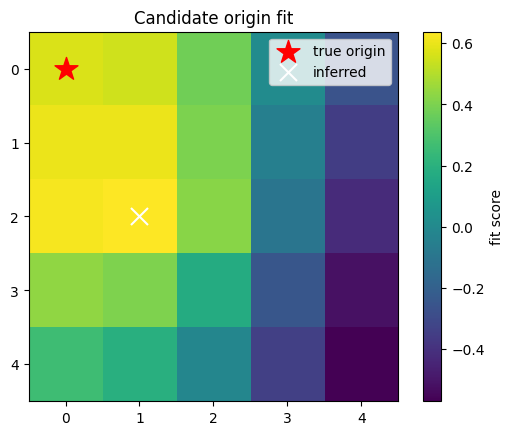

In [20]:
# Try every cell as the candidate origin
scores = np.zeros((n, n))
for r0 in range(n):
    for c0 in range(n):
        d = np.array([[abs(r-r0) + abs(c-c0) for c in range(n)] for r in range(n)])
        # more negative correlation = better "diversity falls with distance" fit
        scores[r0, c0] = -np.corrcoef(d.ravel(), het.ravel())[0, 1]

best = np.unravel_index(np.argmax(scores), scores.shape)
err = abs(best[0]-origin[0]) + abs(best[1]-origin[1])

print("True origin:    ", origin)
print("Inferred origin:", best)
print("Error (grid steps):", err)

plt.imshow(scores); plt.colorbar(label="fit score")
plt.scatter(origin[1], origin[0], marker="*", s=300, c="red", label="true origin")
plt.scatter(best[1], best[0], marker="x", s=150, c="white", label="inferred")
plt.legend(); plt.title("Candidate origin fit"); plt.show()

uniform        mean error = 1.47 grid steps, exact hits = 17%
heterogeneous  mean error = 1.47 grid steps, exact hits = 17%


/tmp/ipykernel_1371/4014304435.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(results.values(), labels=results.keys())


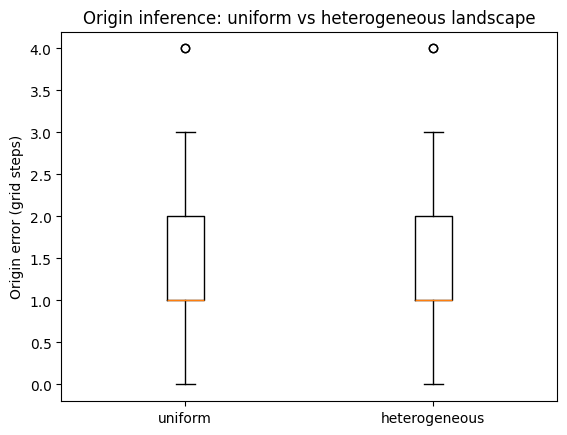

In [21]:
def run_once(n, origin, seed, hetero=False, het_width=0, m=0.01, step_gens=50,
             Nb=5, w=40, mu=1e-7, L=1e6):
    rng = np.random.default_rng(seed)
    Ne_grid = np.clip(rng.uniform(100-het_width, 100+het_width, (n, n)), 10, None)
    idx = lambda r, c: r*n + c

    dem = msprime.Demography()
    for r in range(n):
        for c in range(n):
            dem.add_population(name=f"d{idx(r,c)}", initial_size=Ne_grid[r, c])
    for r in range(n):
        for c in range(n):
            for dr, dc in [(1,0), (-1,0), (0,1), (0,-1)]:
                rr, cc = r+dr, c+dc
                if 0 <= rr < n and 0 <= cc < n:
                    dem.set_migration_rate(f"d{idx(r,c)}", f"d{idx(rr,cc)}", m)

    dmax = max(abs(r-origin[0]) + abs(c-origin[1]) for r in range(n) for c in range(n))
    for r in range(n):
        for c in range(n):
            d = abs(r-origin[0]) + abs(c-origin[1])
            if d == 0:
                continue
            t_found = (dmax - d + 1) * step_gens
            pr, pc = (r-1, c) if r > origin[0] else (r, c-1) if c > origin[1] else (r, c+1)
            dem.add_population_parameters_change(
                time=t_found - w, population=f"d{idx(r,c)}", initial_size=Nb)
            dem.add_mass_migration(time=t_found, source=f"d{idx(r,c)}",
                                   dest=f"d{idx(pr,pc)}", proportion=1)
    dem.sort_events()

    ts = msprime.sim_ancestry(samples={f"d{i}": 5 for i in range(n*n)},
                              demography=dem, sequence_length=L,
                              recombination_rate=1e-8, random_seed=seed)
    ts = msprime.sim_mutations(ts, rate=mu, random_seed=seed)
    het = np.array([ts.diversity(sample_sets=[ts.samples(population=i)])
                    for i in range(n*n)]).reshape(n, n)

    # infer origin
    best, best_score = None, -np.inf
    for r0 in range(n):
        for c0 in range(n):
            d = np.array([[abs(r-r0) + abs(c-c0) for c in range(n)] for r in range(n)])
            s = -np.corrcoef(d.ravel(), het.ravel())[0, 1]
            if s > best_score:
                best, best_score = (r0, c0), s
    return abs(best[0]-origin[0]) + abs(best[1]-origin[1])

n_reps = 30
rng = np.random.default_rng(42)
results = {"uniform": [], "heterogeneous": []}
for i in range(n_reps):
    origin_i = (int(rng.integers(n)), int(rng.integers(n)))
    results["uniform"].append(run_once(n, origin_i, seed=i+1, hetero=False))
    results["heterogeneous"].append(run_once(n, origin_i, seed=i+1, hetero=True))

for k, v in results.items():
    print(f"{k:14s} mean error = {np.mean(v):.2f} grid steps, "
          f"exact hits = {np.mean(np.array(v)==0):.0%}")

plt.boxplot(results.values(), labels=results.keys())
plt.ylabel("Origin error (grid steps)")
plt.title("Origin inference: uniform vs heterogeneous landscape")
plt.show()

width ±0: mean error 1.45, exact hits 12%
width ±30: mean error 1.85, exact hits 15%
width ±60: mean error 1.68, exact hits 20%
width ±90: mean error 1.95, exact hits 12%


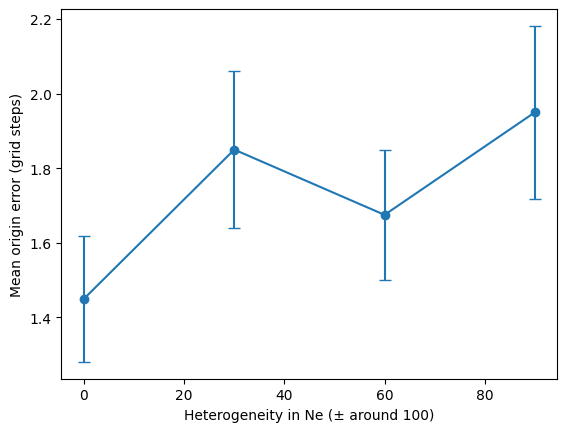

In [22]:
widths = [0, 30, 60, 90]
n_reps = 40
rng = np.random.default_rng(11)
origins = [(int(rng.integers(n)), int(rng.integers(n))) for _ in range(n_reps)]

errs = {}
for wd in widths:
    errs[wd] = np.array([run_once(n, origins[i], seed=2000+i, het_width=wd)
                         for i in range(n_reps)])
    print(f"width ±{wd}: mean error {errs[wd].mean():.2f}, exact hits {np.mean(errs[wd]==0):.0%}")

plt.errorbar(widths, [errs[w].mean() for w in widths],
             yerr=[errs[w].std()/np.sqrt(n_reps) for w in widths], marker="o", capsize=4)
plt.xlabel("Heterogeneity in Ne (± around 100)"); plt.ylabel("Mean origin error (grid steps)")
plt.show()

In [23]:
from scipy.stats import spearmanr, wilcoxon

# Trend across all widths (pooled, paired by replicate index)
w_all = np.repeat(widths, n_reps)
e_all = np.concatenate([errs[w] for w in widths])
rho, p = spearmanr(w_all, e_all)
print(f"Spearman rho = {rho:.3f}, p = {p:.3f}")

# Endpoint comparison, paired
print("±0 vs ±90 Wilcoxon p =", wilcoxon(errs[0], errs[90]).pvalue)

Spearman rho = 0.118, p = 0.139
±0 vs ±90 Wilcoxon p = 0.17124401522804067
